In [1]:
from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import *
import matplotlib.pyplot as plt

In [49]:
tx = Loop.square(3)
rx = Receiver(x=9.)
waveform = Waveform.example()
# recfilter = FilterChain([ButterworthFilter(2.4e5,1),
#                          ButterworthFilter(6.2e5,1),
#                          ButterworthFilter(4.5e5,1)])

In [50]:
def logify_forward(cls):
    class LogFwr(cls):
        def __call__(self, *args, **kwargs):
            return super().__call__(*args, **kwargs).log10()
    return LogFwr

LFL6 = logify_forward(ForwardLaplace6)

In [51]:
times = torch.logspace(-5,-3, 32)
fwrTD = LFL6(tx, rx,times,waveform=waveform)

/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [52]:
def compute_relstd(t_gates, dbdt, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, current=1., relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = dbdt*current
    std_rel = abs_noise/y
    relstd_tot = torch.sqrt(std_rel**2 + relative_noise**2)
    return relstd_tot

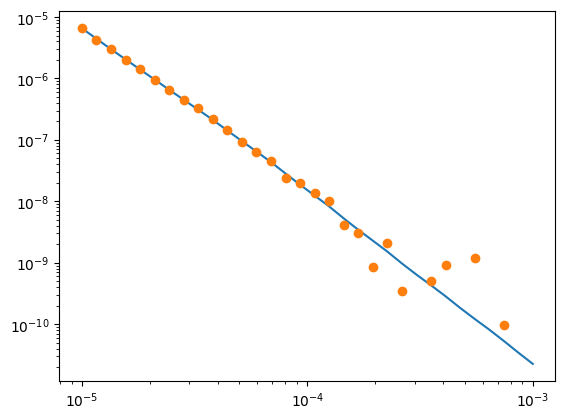

In [53]:
rho = torch.tensor([20, 80, 40])
thk = torch.tensor([30,20.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**fwrTD(rho, thk)
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=30.)
d_err = torch.log10(1. + d_relerr)
d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr


plt.figure()
plt.loglog(fwrTD.times, dbdt_true, '-', label='Observed')
plt.loglog(fwrTD.times, d_obs, 'o', label='Observed')

d_obs = torch.abs(d_obs).log10()

In [54]:
class ParamDependentDamping(BaseInversion):
    max_step                         = 3
    min_step                         = 0.1
    damping_factor                   = 3.
    damp_initmax                     = 1e6  
    damp_exponent                    = 6
    data_predicted                   = None
    vertical_smoothness              = 0.1

        
    @property
    def damp_matrix(self):
        diag_GTG = self.GtG.diagonal()
        damp = torch.empty_like(diag_GTG)
        for i,pslice in enumerate(self.model.pslice):
            if self.damp_exponent[i]>0:
                max_GTG = diag_GTG[pslice].max()
                #if self.iteration<1:
                max_GTG /= self.diag_normalizer
                print(f'max GTG for pslice {i}: {max_GTG*self.damping_factor**(self.damp_exponent[i])}')
                damp[pslice] =  max_GTG*self.damping_factor**(self.damp_exponent[i])
            else:
                damp[pslice] = 0.
        if self.iteration==0: damp = torch.clamp(damp, max=self.damp_initmax)
        return damp*self.Imod

    def setup_matrices(self):
        n_ptypes = len(self.model.pslice)
        self.mvec = self.m*1.
        self.diag_normalizer = self.diag_normalizer
        self.Cdi = torch.diag(self.recip_error_squared)
        self.Cm = torch.eye(len(self.mvec)-n_ptypes, dtype=torch.float64) / (torch.log(torch.tensor(1 + self.vertical_smoothness, dtype=torch.float64)) ** 2)
        self.Imod = torch.eye(self.nM, device=self.mvec.device)
        self._current_mvec = self.mvec*1.1 if torch.all(self.mvec!=0) else torch.ones_like(self.mvec)# make sure the jacobian is calculated at least once
        self._G = None
        self.damp_exponent = torch.ones(len(self.model.pslice))*self.damp_exponent
        self.max_step = torch.ones(len(self.model.pslice))*self.max_step
        self.min_step = torch.ones(len(self.model.pslice))*self.min_step
        self.set_device(self.mvec.device)
        H = self.model.H().to(torch.double)
        self.HtH = H.T @ self.Cm @ H

    @property
    def stop_inversion(self):
        if self.iteration > 1 and self.misfits[-1]>self.misfits[-2]>self.misfits[-3]==min(self.misfits):
            return True
        else: return super().stop_inversion
    
    def calc_dm(self):
        r_data  = self.G.T @ self.Cdi @ (self.data_observed-self.data_predicted)
        r_data += self.HtH @ self.mvec.to(torch.double)
        Aown    = self.GtG + self.damp_matrix + self.HtH
        return solve(Aown, r_data)
    
    def check_dm(self, dM, ):
        pass
    # def calc_dm(self):
    #     r_data = self.G.T @ self.Cdi @ (self.data_observed-self.data_predicted)
    #     Aown = self.GtG + self.damp_matrix + self.HtH
    #     return solve(Aown, r_data)    

    def invert(self, iter_cap=10, **kwargs):
        self.setup_matrices()

        self.iteration   = 0
        self.iter_cap    = iter_cap
        self.misfits     = [np.inf]

        self.data_predicted = self.mforward(self.mvec)
        self.misfits.append(self.misfit())
        
        while not self.stop_inversion:
            if self.misfits[-1]>self.misfits[-2]:
                self.mvec -= dM
                self.damp_exponent += 2
            damping_attempts = 0
            test_damping = [True]*len(self.model.pslice)

            while any(test_damping):
                dM   = self.calc_dm()
                dM_abs = torch.abs(dM)
                for i,pslice in enumerate(self.model.pslice):
                    #dM_abs[pslice] = dM_abs[pslice].max()
                    if dM_abs[pslice].max()>self.max_step[i] and not damping_attempts>20:
                        self.damp_exponent[i] += 1
                        damping_attempts+=1
                        test_damping[i] = True
                    # Should this be in the dampening state or between each iteration. If here, should it count as a damping attempt?
                    elif dM_abs[pslice].min()<self.min_step[i] and self.damp_exponent[i]>0 and not damping_attempts>20:
                        self.damp_exponent[i] -= 1
                        damping_attempts+=1
                        test_damping[i] = True
                    elif damping_attempts>20:
                        test_damping[i] = False
                    elif self.damp_exponent[i]<=0:
                        self.damp_exponent[i] = 0
                        test_damping[i] = False
                    else:
                        
                        test_damping[i] = False
                    damping_attempts+=1

            if self.misfits[-1]>self.misfits[-2] or (abs(self.misfits[-2]-self.misfits[-1]) / self.misfits[-1]) < self.data_misfit_minimum_change and any(abs(1-self.max_step/self.min_step)>0.001):
                if not any(abs(1-self.max_step/self.min_step)<0.001): # Step down if the misfit is not improving and max_step is larger than min_step
                    for i,pslice in enumerate(self.model.pslice):
                        self.max_step[pslice] -= 1
                        if all(self.max_step[pslice] < self.min_step[pslice]):
                            self.max_step[pslice] = self.min_step[pslice]
            else:
                for i,pslice in enumerate(self.model.pslice):
                    self.max_step[i] += 0.5
                self.diag_normalizer *= 3


            print('damping attempts:', damping_attempts)
            self.mvec      += torch.nan_to_num(dM)

            self.iteration += 1
            self.data_predicted  = self.mforward(self.mvec)
            self.misfits.append(self.misfit())
            self.damp_exponent += -1
            self.log("{:03d}\tmisfit:\t{:2.2f}".format(self.iteration, self.misfits[-1]))
        
        if self.iteration==iter_cap: 
            self.log('reached iteration cap..')

        self.log('\n'+str(self.iteration))
        mres = self.model.copy()
        mres.values = mres.modelize(self.mvec)
        return mres    


In [55]:
res_start = LogResistivity.smooth(torch.ones(31)*50, torch.cumsum(torch.logspace(0.5,1.5,30), 0))
inv = Tikhonov(d_obs, d_err, res_start, fwrTD)
res_mod = inv.invert(iter_cap=10)

001	misfit:	1.59
002	misfit:	1.36
003	misfit:	1.35
004	misfit:	1.34
005	misfit:	1.34
006	misfit:	1.33
007	misfit:	1.32
008	misfit:	1.32
009	misfit:	1.31
010	misfit:	1.30
reached iteration cap..
reached iteration cap..

10


In [56]:
res_mod.values

[tensor([19.3731, 21.2100, 21.3824, 18.3572, 17.3830, 21.6857, 29.8692, 38.6378,
         45.5952, 50.1035, 52.4742, 53.2728, 53.0663, 52.3374, 51.4432, 50.6100,
         49.9569, 49.5282, 49.3191, 49.2927, 49.3932, 49.5594, 49.7375, 49.8898,
         49.9980, 50.0599, 50.0838, 50.0822, 50.0671, 50.0481, 50.0318]),
 tensor([ 3.1623,  3.4236,  3.7065,  4.0128,  4.3444,  4.7034,  5.0921,  5.5129,
          5.9685,  6.4617,  6.9956,  7.5737,  8.1996,  8.8772,  9.6108, 10.4050,
         11.2648, 12.1957, 13.2035, 14.2946, 15.4759, 16.7547, 18.1393, 19.6383,
         21.2611, 23.0181, 24.9202, 26.9795, 29.2090, 31.6228])]

[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

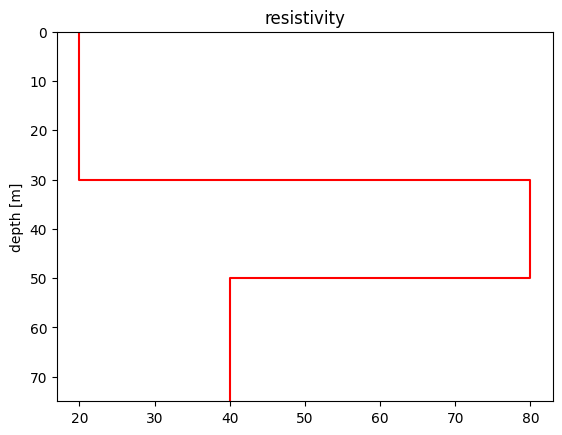

In [57]:
mod_true.plot(color='red', label='True model')
#ax = res_mod.plot()


array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'phi'}>, <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'c'}>], dtype=object)

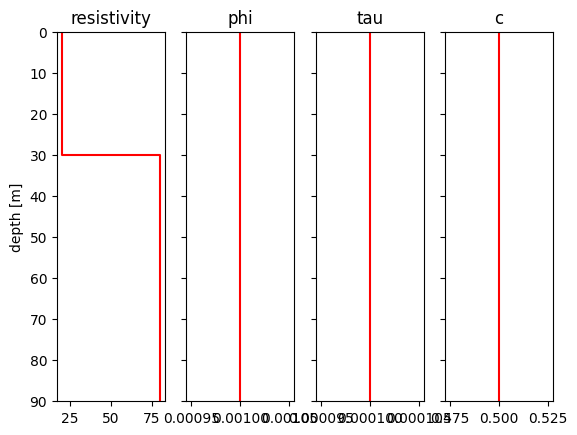

In [58]:
mpa1 = LogMPA.few_layers([
    torch.tensor([20., 80., 80.]),
    torch.tensor([0.001, 0.001, 0.001]),
    torch.tensor([1e-4, 1e-4, 1e-4]),
    torch.tensor([0.5, 0.5, 0.5])
],  torch.tensor([30, 30]))


mpa1.plot(label='MPA2 True Model', color='red')

In [59]:
fwrmpa = ForwardLaplace6.mpa(tx, rx, fwrTD.times, waveform=waveform, filterfunc=recfilter)
mpa = logify_forward(fwrmpa.__class__)
fwrmpa = mpa(tx, rx, fwrTD.times, waveform=waveform, filterfunc=recfilter)
#fwrmpa = ForwardLaplace6.mpa(tx, rx, fwrTD.times, waveform=waveform, filterfunc=recfilter)

dbdt_true: tensor([1.1590e-05, 7.1841e-06, 4.4010e-06, 2.7204e-06, 1.7117e-06, 1.0928e-06,
        7.0857e-07, 4.7371e-07, 3.2307e-07, 2.1926e-07, 1.4700e-07, 9.9213e-08,
        6.7353e-08, 4.5441e-08, 2.9608e-08, 1.9369e-08, 1.2805e-08, 8.4321e-09,
        5.2982e-09, 3.3815e-09, 2.1998e-09, 1.4195e-09, 8.7598e-10, 5.5496e-10,
        3.5977e-10, 2.2898e-10, 1.4107e-10, 8.9573e-11, 5.8024e-11, 3.6394e-11,
        2.2430e-11, 1.4165e-11], dtype=torch.float64)


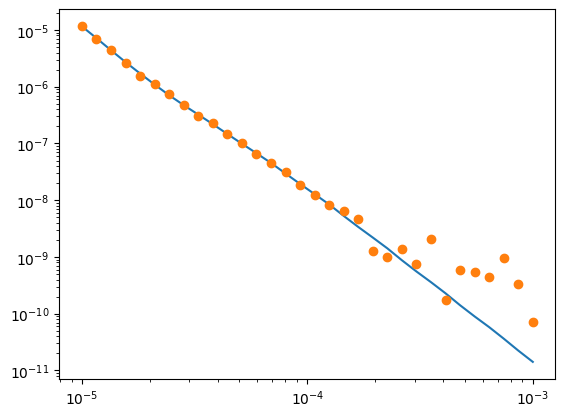

In [60]:
dbdt_true = 10**fwrmpa(*mpa1.mod)
print('dbdt_true:', dbdt_true)
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=30.)
d_obs = torch.abs(dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr)


plt.figure()
plt.loglog(fwrmpa.times, dbdt_true, '-', label='Observed')
plt.loglog(fwrmpa.times, d_obs, 'o', label='Observed')
d_obs = torch.abs(d_obs).log10()

In [61]:
res_start = LogMPA.smooth([torch.ones(31)*10,
                           torch.ones(31)*0.005,
                           torch.ones(31)*5e-4,
                           torch.ones(31)*0.25
                           ], torch.cumsum(torch.logspace(0,1,30), 0))
inv = BaseInversion(d_obs, d_err, res_start, fwrmpa)
# inv.data_misfit_acceptance_threshold = 0.9
res_mpa = inv.invert(iter_cap=10)

001	misfit:	5.79
002	misfit:	3.05
003	misfit:	2.36
004	misfit:	2.02
005	misfit:	1.79
006	misfit:	1.62
007	misfit:	1.50
008	misfit:	1.40
009	misfit:	1.32
010	misfit:	1.24
reached iteration cap..
reached iteration cap..

10


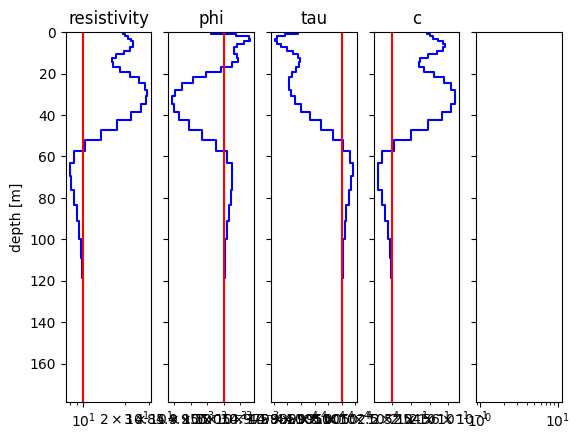

In [62]:
axs = res_mpa.plot(label='MPA Inversion Result', color='blue')
res_start.plot(axs=axs, color='red', label='True MPA Model')
for ax in axs:
    ax.set_xscale('log')

In [ ]:
class BaseInversion:
    jac_perturbation_fraction        = 0.02
    data_misfit_acceptance_threshold = 0.8
    data_misfit_minimum_change       = 0.001
    diag_normalizer                  = 5.e3
    max_step                         = 0.5
    min_step                         = 0.001
    damping_factor                   = 3.
    damp_exponent                    = 6
    data_predicted                   = None

    def __init__(self, data_observed, data_error, starting_model,  forward_operator, logger=print):
        """Create an inversion object, the necessary """
        self.data_observed       = data_observed
        self.data_error          = data_error
        self.model               = starting_model
        self.forward             = forward_operator
        self.result              = None
        self.nM                  = len(self.m)
        self.nD                  = len(data_observed)
        self.recip_error_squared = 1./self.data_error**2
        self.log                 = logger


    def set_device(self, device):
        for var_name in vars(self):
            var = getattr(self, var_name)
            if torch.is_tensor(var):
                setattr(self, var_name, var.to(device))
            elif isinstance(var, list):
                for i, v in enumerate(var):
                    if torch.is_tensor(v):
                        var[i] = v.to(device)

    @property
    def m(self):
        return self.model.vec
    
    def data_misfit(self):
        if self.data_predicted is None: self.data_predicted = self.mforward(self.mvec)
        return (self.data_observed-self.data_predicted)**2 * self.recip_error_squared

    def misfit(self):
        return torch.sqrt(self.data_misfit().mean())
    
    def jacobian(self, mvec):
        dm   = mvec*self.jac_perturbation_fraction
        dm[dm==0] = self.jac_perturbation_fraction
        if self.data_predicted is None: self.data_predicted = self.mforward(mvec)
        m_pert    = torch.diag(dm) + mvec[:, None]
        d_data    = self.mforward(m_pert)
        Gt = (d_data - self.data_predicted) / dm[:, None]
        return Gt.T
    
    @property
    def G(self):
        if torch.any(self.mvec!=self._current_mvec) or self._G is None:
            self._G = self.jacobian(self.mvec)
            self._current_mvec = self.mvec*1.
            self._GtG = self._G.T @ self.Cdi @ self._G
        return self._G
    
    @property
    def GtG(self):
        if torch.any(self.mvec!=self._current_mvec):
            self._G = self.jacobian(self.mvec)
            self._current_mvec = self.mvec*1.
            self._GtG = self._G.T @ self.Cdi @ self._G
        return self._GtG

    @property
    def damp_matrix(self):
        
        diag_GTG = self.GtG.diagonal()
        if self.iteration==0:
            max_GTG = [diag_GTG[pslice].max()/self.diag_normalizer for pslice in self.model.pslice]
        else:
            max_GTG = [diag_GTG[pslice].max() for pslice in self.model.pslice]
        damp = torch.empty_like(diag_GTG)
        #mathias code
        for i,pslice in enumerate(self.model.pslice):
            if self.damp_exponent[i]>0:
                damp[pslice] =  max_GTG[i]*self.damping_factor**(self.damp_exponent[i]-1)
            else:
                damp[pslice] = 0.
        #max_diag = self.GtG.diagonal().max()/self.diag_normalizer
        #if self.damp_exponent>0:
        #    damp = max_diag*self.damping_factor**(self.damp_exponent-1)
        #else:
        #    damp = 0.
        return damp*self.Imod

    def setup_matrices(self):
        self.mvec = self.m*1.
        self.Cdi = torch.diag(self.recip_error_squared)
        self.Imod = torch.eye(self.nM, device=self.mvec.device)
        self._current_mvec = self.mvec*1.1 if torch.all(self.mvec!=0) else torch.ones_like(self.mvec)# make sure the jacobian is calculated at least once
        self._G = None
        self.damp_exponent = torch.ones(len(self.model.pslice))*self.damp_exponent
        self.max_step = torch.ones(len(self.model.pslice))*self.max_step
        self.set_device(self.mvec.device)

    def Cm(self, mvec):
        G = self.jacobian(mvec)
        return inv( G.T @ np.diag(self.recip_error_squared) @ G )

    def mforward(self, mvec):
        return self.forward(*self.model.modelize(mvec))

    @property
    def stop_inversion(self):
        if self.iteration<=1:
            return False
        if (abs(self.misfits[-2]-self.misfits[-1]) / self.misfits[-1]) < self.data_misfit_minimum_change:
            self.log(f'misfit change is less than {self.data_misfit_minimum_change}')
            return True
        if self.misfits[-1]<self.data_misfit_acceptance_threshold:
            return True
        #if self.misfits[-1]>self.misfits[-2] and self.misfits[-3]==min(self.misfits):
        #    return True
        if self.iteration>=self.iter_cap:
            self.log('reached iteration cap..')
            return True
        return False

    def calc_dm(self):
        r_data = self.G.T @ self.Cdi @ (self.data_observed-self.data_predicted)
        Aown = self.GtG + self.damp_matrix
        return solve(Aown, r_data)

    def invert(self, iter_cap=10, **kwargs):
        self.setup_matrices()

        self.iteration   = 0
        self.iter_cap    = iter_cap
        self.misfits     = [np.inf]

        self.data_predicted = self.mforward(self.mvec)
        self.misfits.append(self.misfit())

        while not self.stop_inversion:
            if self.misfits[-1]>self.misfits[-2]:
                self.mvec -= dM
                self.damp_exponent += 2
            damping_attempts = 0
            test_damping = True

            while test_damping:
                dM   = self.calc_dm()
                dM_abs = torch.abs(dM)
                #Mathias code
                for i,pslice in enumerate(self.model.pslice):
                    #dM_abs[pslice] = dM_abs[pslice].max()
                    if dM_abs[pslice].max()>self.max_step:
                        self.damp_exponent[i] += 1
                        damping_attempts+=1
                        test_damping = True
                    elif dM_abs[pslice].min()<self.min_step and self.damp_exponent[i]>0:
                        self.damp_exponent[i] -= 1
                        damping_attempts+=1
                        test_damping = True
                    elif damping_attempts>20:
                        test_damping = False
                    elif self.damp_exponent[i]<0:
                        self.damp_exponent[i] = 0
                        test_damping = False
                    else:
                        #self.damp_exponent[i] -= 1
                        test_damping = False
            
               # if torch.any(dM_abs>self.max_step):
               #     self.damp_exponent += 1
               #     damping_attempts+=1
               # elif damping_attempts>20:
               #     test_damping = False
               # else:
               #     test_damping = False
                
                
            
            if damping_attempts==0 and self.iteration>1:
                self.max_step += 0.5
            elif damping_attempts==20:
                self.max_step -= 0.1
        
            self.mvec      += torch.nan_to_num(dM)
            self.iteration += 1
            self.data_predicted  = self.mforward(self.mvec)
            self.misfits.append(self.misfit())
            self.damp_exponent += -1
            self.log("{:03d}\tmisfit:\t{:2.2f}".format(self.iteration, self.misfits[-1]))
                                
        if self.iteration==iter_cap: self.log('reached iteration cap..')
        self.log('\n'+str(self.iteration))
        mres = self.model.copy()
        mres.values = mres.modelize(self.mvec)
        return mres
